In [1]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import sqrt
from numpy import std
from numpy import mean
import pandas as pd
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
d=pd.read_csv('diabetes.csv')
d

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
d.shape

(768, 9)

In [4]:
d.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [5]:
from sklearn.model_selection import train_test_split

X = d.drop('Outcome', axis=1)
y = d.Outcome
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [6]:
model = DecisionTreeClassifier()
model = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.7056277056277056


In [7]:
model = DecisionTreeClassifier()
model = model.fit(X_train, y_train)
y_pred = model.predict(X_test)
cv = KFold(n_splits=10,shuffle=True)

y_pred = model.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test,y_pred))

Accuracy: 0.7186147186147186


In [8]:
scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)

In [9]:
scores

array([0.72727273, 0.75324675, 0.77922078, 0.79220779, 0.7012987 ,
       0.66233766, 0.75324675, 0.68831169, 0.72368421, 0.73684211])

In [10]:
print('Accuracy: %.3f (%.3f)' % (mean(scores), std(scores)))


Accuracy: 0.732 (0.038)


Text(0.5, 1.0, 'Accuraccy vs CV graph')

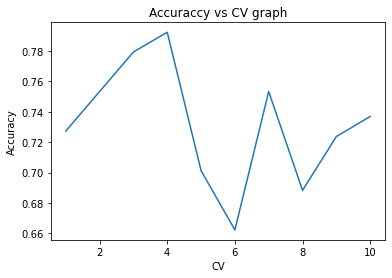

In [11]:
x1 = [1,2,3,4,5,6,7,8,9,10]
y1 = scores
plt.plot(x1, y1)
plt.xlabel('CV')
plt.ylabel('Accuracy')
plt.title('Accuraccy vs CV graph')


In [12]:
from sklearn.metrics import classification_report
model = model.fit(X_train, y_train)
prediction = model.predict(X_test)

target_names = ['0','1']
print(classification_report(y_test, prediction.reshape(-1,1), target_names=target_names))


              precision    recall  f1-score   support

           0       0.80      0.73      0.76       151
           1       0.56      0.65      0.60        80

    accuracy                           0.70       231
   macro avg       0.68      0.69      0.68       231
weighted avg       0.71      0.70      0.71       231



In [14]:
#Hyper parametric tunning

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
 
#Creating the hyperparameter grid
param_grid = {"splitter":["best","random"],
            "max_depth" : [1,3,5,7,9,11,12],
           "min_samples_leaf":[1,2,3,4,5,6,7,8,9,10],
           "min_weight_fraction_leaf":[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9],
           "max_features":["auto","log2","sqrt",None],
           "max_leaf_nodes":[None,10,20,30,40,50,60,70,80,90] }

 
# Instantiating logistic regression classifier
model = DecisionTreeClassifier()

# Instantiating the GridSearchCV object
classifier_cv = GridSearchCV(model, param_grid, cv = 5)
classifier_cv.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [1, 3, 5, 7, 9, 11, 12],
                         'max_features': ['auto', 'log2', 'sqrt', None],
                         'max_leaf_nodes': [None, 10, 20, 30, 40, 50, 60, 70,
                                            80, 90],
                         'min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'min_weight_fraction_leaf': [0.1, 0.2, 0.3, 0.4, 0.5,
                                                      0.6, 0.7, 0.8, 0.9],
                         'splitter': ['best', 'random']})

In [15]:
classifier_cv.best_params_

{'max_depth': 5,
 'max_features': 'log2',
 'max_leaf_nodes': 60,
 'min_samples_leaf': 4,
 'min_weight_fraction_leaf': 0.1,
 'splitter': 'best'}

In [16]:
model1 = DecisionTreeClassifier(random_state=1,max_depth=11,
 max_features='log2',
 max_leaf_nodes= 20,
 min_samples_leaf= 8,
 min_weight_fraction_leaf= 0.1,
 splitter= 'best')
model1 = model1.fit(X_train,y_train)
y1_pred = model1.predict(X_test)

In [17]:
c= cross_val_score(model1, X, y, scoring='accuracy', cv=cv, n_jobs=-1)

In [18]:
mean(c)

0.7109876965140124

In [ ]:
#Conclusion:
#Here we have used k-fold for the Decsion tree to avaluate the model
#We have done hyper parameter tuning and can conclude that accuracy with 10 splits is better than the accuracy 
#with gridsearch 5 k-folds.